# PD46: is the decline in draft rates supported by the data?

This notebook begins with a simple comparison between two specified peer environments. It does not automatically choose the highest point of a curve and compare everything else against that point.

**Run the settings, loading, and preview cells first.** Read the counts and graph before turning on the first statistical test. Each later step has its own switch. No downloads or manuscript edits occur.

The first population is the verified 2009-2021 basketball cohort: one final observed season per player, all eligible colleges, minimum 20 minutes and 10 team-season games. The outcome is whether the player was **ever drafted**, not whether he was drafted that season. Teammate performance excludes the focal player. This is the population behind the original all-player final-season figure and its top-7% companion, not the repeated-player-season populations of original mosaic panels 7 and 8.

These comparisons are **exploratory**. We have already examined related graphs. The initial 60th-80th versus 80th-100th percentile ranges below are proposed working defaults, not a previously agreed peak or a preregistered test. Changing bands after seeing results adds to that exploration. A nominal p-value does not account for those earlier searches.

**New: Section 4A tests the peak-to-tail decline we identified on the curve.** Run sections 1-3, then enable `RUN_PEAK_TAIL_TEST` and run 4A. You can leave `RUN_FIRST_TEST` off: it answers the earlier, broader percentile-range question.


## 1. Visible settings

The first question is: among the highest-performing players, is the draft rate lower in the strongest peer environments than in the comparison range?

Percentiles for peer environments are calculated from **all eligible players** in the selected year window, before filtering individual performance. They are player-weighted percentiles, not percentiles of equally weighted colleges. Equal scores stay together, so group sizes need not match exactly.


In [1]:
SETTINGS = {
    "years": [2009, 2021],          # Restrict the verified final-season cohort; original score scaling is retained.
    "top_percent": 7.0,            # Top 7% by individual points-per-minute z score; 100 includes all players.
    "peer_percentiles": [60, 80],  # Compare peer percentile 60 up to 80 against percentile 80 through 100.
    "plot_bin_counts": [8, 12, 16, 24],  # Show EVERY listed resolution, using both equal widths and quantiles.
    "split_seed": 46,              # Reproducible college allocation to three subsets; do not search seeds.
}
RUN_FIRST_TEST = True              # Raw difference in rates, with uncertainty allowing dependence within colleges.
RUN_ADJUSTED_TEST = False           # Later: account for own performance and season in a linear probability model.
RUN_RESOLUTION_PLOTS = False        # Later: change graph resolution while retaining the SAME rate comparison.
RUN_THREE_SUBSETS = False           # Later: descriptive repeatability across three disjoint sets of colleges.
SAVE_RESULTS = True                # Write timestamped aggregate outputs only when you run the final save cell.

# New peak-to-tail test. These options do not move the 16 original bin boundaries.
RUN_PEAK_TAIL_TEST = True          # Turn on to compare bin 14 with bins 15+16, adjusted for all 14 locations.
PEAK_BOOTSTRAP_REPETITIONS = 9999   # Reproducible noise draws, not new players or new datasets downloaded.
PEAK_BOOTSTRAP_SEED = 46           # Keep fixed; do not search seeds for a smaller p-value.

# Panel 7 retains its original population and binning, independent of SETTINGS above.
RUN_PANEL7_TEST = False
PANEL7_BOOTSTRAP_REPETITIONS = 9999
PANEL7_BOOTSTRAP_SEED = 46


## 2. Load and verify the existing local data

This checks the historical cohort totals and the original 16 overall bin counts. If they no longer match, it stops rather than silently treating a changed source as the same cohort. It does not contact a website.


In [2]:
from pathlib import Path
import sys, importlib, json
from IPython.display import display, Image
import matplotlib.pyplot as plt

# Works when launched from this folder, the figure folder, or the repository root.
relative = Path("3-Master_Plan/VECTOR_work/new_VECTOR_work/manuscript_figures/section_4_5/pd46_statistics")
candidates = [Path.cwd(), Path.cwd()/"pd46_statistics", Path.cwd()/"manuscript_figures/section_4_5/pd46_statistics"]
candidates += [root/relative for root in [Path.cwd(), *Path.cwd().parents]]
MODULE_DIR = next((q for q in candidates if (q/"pd46_comparisons.py").exists()), None)
if MODULE_DIR is None:
    raise FileNotFoundError("Open this notebook from its saved folder or from the repository root.")
sys.path.insert(0, str(MODULE_DIR))
import pd46_comparisons as analysis
analysis = importlib.reload(analysis)
source_panel, original_edges = analysis.load_verified_cohort()
print(f"Loaded {len(source_panel):,} distinct players. No statistical test has run.")


Reconstructing saved-specification basketball cohort from local data...
Last-season cross-section · 54,582 → 22,795 rows · 22,795 athletes
Verified historical cohort totals, top-7% cutoff, and all 16 original overall bin counts.
Loaded 22,795 distinct players. No statistical test has run.


## 3. Preview the comparison before testing it

The graph shows the two observed rates. The table also shows the player counts, number drafted, number of colleges, and average individual performance in each range. A top-7% band still contains performance differences, so the two ranges may not contain equally strong individuals.

Blue is the comparison range. Red is the strongest peer range. We do not call blue the peak: the code has not searched for a peak. A lower red bar would be consistent with a decline over this particular part of the peer distribution; it would not by itself establish an inverted U across the whole range.

The second graph places these same ranges on the original 16-bin curve. Its dashed lines are combined player-level rates, not averages of the bin heights. Check whether a shaded range contains both a peak and a downturn before interpreting the first test.


Eligible cohort: 22,795 players; own-performance band: 1,596 players.
Own-performance cutoff: 1.6467
Peer-score boundaries: [0.0536, 0.218]


,group,players,ever_drafted,draft_rate_percent,colleges,mean_own_performance,mean_peer_performance
0,Comparison: peer percentiles 60 to 80,265,50,18.868,163,2.202,0.129
1,Strongest: peer percentiles 80 to 100,260,48,18.462,116,2.166,0.379


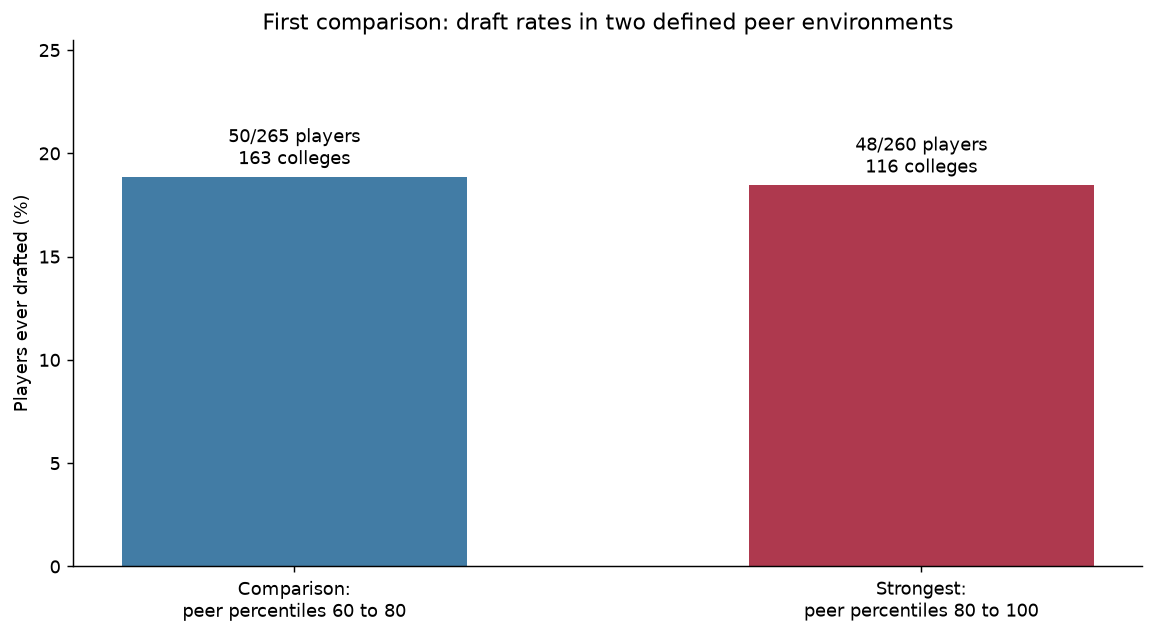

Preview complete. No statistical test has run.


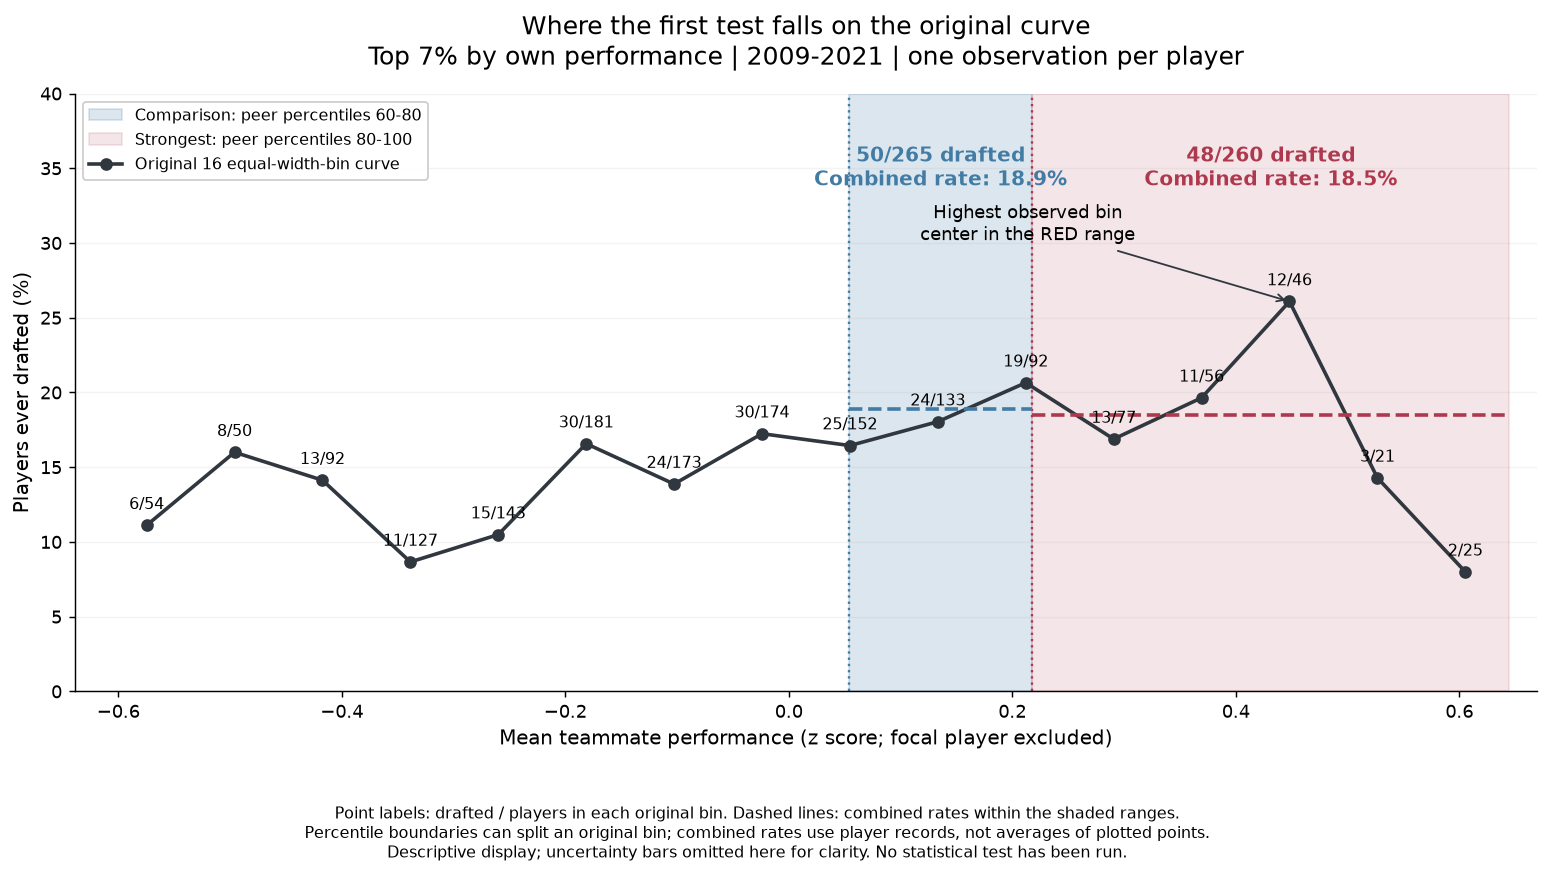

In [3]:
population, band, comparison, summary, provenance = analysis.prepare(source_panel, SETTINGS)
settings_at_preview = json.dumps(SETTINGS, sort_keys=True)
tables = {"preview": summary}
figures = {}

def require_current_preview():
    if json.dumps(SETTINGS, sort_keys=True) != settings_at_preview:
        raise RuntimeError("Settings changed. Rerun the preview before continuing.")

def show_figure(fig):
    # Explicit PNG display also works when a notebook's matplotlib backend shows only a Figure label.
    import io
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

print(f"Eligible cohort: {len(population):,} players; own-performance band: {len(band):,} players.")
print(f"Own-performance cutoff: {provenance['performance_cutoff']:.4f}")
print("Peer-score boundaries:", [round(x, 4) for x in provenance['peer_cutoffs']])
display(summary.round(3))
figures["first_comparison"] = analysis.region_plot(summary)
show_figure(figures["first_comparison"])
print("Preview complete. No statistical test has run.")

# Locate the two comparison ranges on the original equal-width curve.
figures["ranges_on_original_curve"], original_curve_bins = analysis.highlighted_original_curve(population, band, original_edges, SETTINGS)
tables["original_curve_bins"] = original_curve_bins
show_figure(figures["ranges_on_original_curve"])


## 4. First test: how large is the difference, and how uncertain is it?

Set `RUN_FIRST_TEST = True` in the settings cell, rerun that cell, then run this cell. The reported difference is **strongest peer range minus comparison range**, in percentage points. A result of -8 would mean eight percentage points fewer drafted in the strongest range.

The null hypothesis is that the two population draft rates are equal. A two-sided test allows evidence in either direction. The 95% interval describes uncertainty under the statistical assumptions; an interval including zero does not establish equal rates. An interval entirely below zero supports a negative association for this specified comparison, subject to the exploratory status.

**Method:** ordinary least squares with an intercept and a binary range indicator reproduces the raw difference in proportions exactly. Uncertainty uses a college-cluster robust covariance estimate, a finite-sample correction, and a Student t reference distribution with number of colleges minus one degrees of freedom. This permits dependence among included players from the same college across seasons. It assumes independence across colleges, an approximation that transfers and shared draft markets can violate. Very few colleges, unequal college sizes, or rare outcomes can make the approximation weak.

This test addresses a difference in rates. Mann-Whitney is not our first choice because the outcome is binary, and its ordinary version would not address college dependence. This is not a test of the congestion mechanism, a causal peer effect, or the full inverted-U shape.


In [4]:
require_current_preview()
if RUN_FIRST_TEST:
    result = analysis.compare(comparison)
    tables["first_test"] = result
    display(result)
    r = result.iloc[0]
    print(f"Strongest minus comparison: {r.tail_minus_comparison_pp:+.2f} percentage points.")
    print(f"95% interval: {r.ci95_low_pp:+.2f} to {r.ci95_high_pp:+.2f} percentage points.")
    print(f"Two-sided exploratory p-value: {r.two_sided_p:.4g}.")
    print("Interpret alongside the counts above; this does not identify a causal effect.")
else:
    tables.pop("first_test", None)
    print("First test is off. Review the preview, then enable RUN_FIRST_TEST when ready.")


,comparison,tail_minus_comparison_pp,ci95_low_pp,ci95_high_pp,two_sided_p,colleges,players,standard_error_pp,t_degrees_of_freedom,caution
0,Raw rate difference,-0.406386,-7.98641,7.173637,0.915921,206,525,3.844598,205,Exploratory; few clusters in either region or ...


Strongest minus comparison: -0.41 percentage points.
95% interval: -7.99 to +7.17 percentage points.
Two-sided exploratory p-value: 0.9159.
Interpret alongside the counts above; this does not identify a causal effect.


## 4A. The question we actually want: does the peak-to-tail decline survive accounting for where we looked?

### New: see both adjustments switched on and off, side by side

The test cell now automatically prints **four versions of the SAME rate difference**, so you do not need to rerun switches or change the observed population:

1. Grouping OFF, location adjustment OFF: each observation treated as independent; only the chosen comparison evaluated for its reported p-value.
2. Grouping OFF, location adjustment ON: same independence assumption, but allow for inspecting 14 candidate peak locations.
3. Grouping ON, location adjustment OFF: account for related observations, without the peak-search correction.
4. Grouping ON, location adjustment ON: account for both.

All four use the same centered multiplier method and fixed bootstrap seed, changing the dependence assumption and search adjustment. They are not Fisher exact tests. The observed decline stays identical. Grouping OFF in panel 7 means **each player-season row** is treated as independent, including repeated seasons of the same person. Grouping ON uses colleges in 4A and linked college groups in 4B. The unadjusted result remains visible even when it differs from the adjusted conclusion; it does not retrospectively make the peak choice independent of the data.

Two count tables follow. The first counts drafted people and the colleges and college-seasons they represent. The second counts the complete denominator, including people not drafted. A college in two different seasons counts twice as college-seasons. Several drafted players at that college in one season count as several players but one college-season. Combined-bin counts are calculated from the union of records, so people or college-seasons appearing in multiple bins are counted only once in the distinct columns. “Ever-drafted rows” can exceed “distinct drafted players” when a player has multiple seasons. The season is the observation season, not necessarily the year of the draft.

The full count CSV also includes distinct drafted **player-season** combinations, a separate quantity from distinct **college-season** combinations. All four statistical versions and the counts are saved by section 8.

**How to run:** complete sections 1-3. In the settings cell, set `RUN_PEAK_TAIL_TEST = True` and rerun that settings cell. Then run the code below. `RUN_FIRST_TEST` can remain `False`. This test uses the original 16 equal-width bins, regardless of `plot_bin_counts` or the earlier `peer_percentiles` settings. Save with section 8 afterward.

### The comparison in everyday English

On the original top-7%, 2009-2021 curve, bin 14 is the highest point: **12 of 46 players drafted, or 26.1%**. The following two bins contain **3 of 21** and **2 of 25**. We combine the people, giving **5 of 46, or 10.9%**. We do not take an unweighted average of those two percentages.

The observed decline is **26.1% minus 10.9%, or about 15.2 percentage points**. Positive numbers in THIS test mean a decline. This is the opposite subtraction order from the earlier broad-range test, which used strongest minus comparison. All headings below explicitly say “decline.”

The target stays at **bin 14 versus bins 15+16**. If you change years or the performance band and bin 14 is no longer highest, the notebook tells you. It does not quietly move the target to a more favorable point. The counts above describe the original settings, not every possible setting.

### Why we cannot just test those 92 players as though we picked them in advance

We noticed the peak after seeing the graph. Random fluctuations can make one point look unusually high. If we look in several places and then test only the most striking one, an ordinary single-comparison p-value gives us too much credit for finding it.

To allow for that, the code considers **all 14 possible locations of this same comparison**: bin 1 versus bins 2+3, bin 2 versus bins 3+4, and so on through bin 14 versus bins 15+16. It keeps every result, including increases and flat comparisons. If a comparison cannot be calculated, the procedure stops rather than silently shrinking the family of tests.

### What the computer does

1. Calculate the decline at every one of the 14 locations.
2. Estimate the uncertainty around each decline, allowing players from the same college to have related outcomes. Colleges remain the dependence groups across seasons.
3. Generate 9,999 sets of **centered statistical fluctuations** using a college-cluster multiplier bootstrap. Think of these as plausible noise around the estimated differences, not as 9,999 new samples of actual players. The same college-level random weight is used for all 14 comparisons in each repetition. This retains the statistical relationships between overlapping comparisons.
4. In each repetition, record the largest noise fluctuation across the 14 comparisons, measured relative to each comparison's uncertainty. We compare standardized differences, not simply the largest percentage-point difference, because small groups are noisier.
5. Compare our observed bin-14 decline with those maxima. The resulting adjusted p-value asks whether our observed evidence is unusual even after allowing 14 opportunities to find a decline.

This is a **one-sided test**: the question is specifically whether the first bin has a higher draft rate than its two following bins. An increase does not count as evidence for a decline. The procedure is an approximate statistical method, not an exact randomization test. It does not assume that every bin's true draft rate is identical; it uses centered estimation errors to construct simultaneous uncertainty for the 14 differences.

### How to read the output

- **Observed decline:** the size of the rate difference, in percentage points. This remains worth reporting even if the test is inconclusive.
- **Adjusted p-value:** the evidence against no decline at our chosen location, accounting for this family of 14 comparisons. Below 0.05 is the conventional evidence threshold used in the printed explanation. It is not a probability that the hypothesis is true, nor a probability that chance caused the observed result.
- **95% simultaneous one-sided lower bound:** the lower end of an uncertainty statement designed to cover all 14 declines together under the method's assumptions. For example, +2 percentage points would support a decline of at least 2 points; -4 would mean that no decline or even an increase remains compatible with this uncertainty statement. It is NOT the lower half of an ordinary two-sided 95% interval. Approximate bootstrap p-values and bounds can differ slightly at a decision boundary because of finite simulation counts.
- **Monte Carlo standard error:** how much numerical uncertainty comes from using a finite number of bootstrap draws. It is separate from uncertainty due to the limited player data. Do not change the seed repeatedly to obtain significance.
- **All 14 comparisons:** the full table makes the search visible. Its unadjusted p-values are supplied for audit, not as substitute conclusions when the adjusted result is inconvenient. The single-step adjustment compares each observed statistic with the maximum across all 14 noise statistics.

A p-value at or above 0.05 means **this procedure did not establish the decline at that threshold**. It does not mean the decline is absent. A p-value below 0.05 is evidence for this association under the assumptions, not proof of congestion or causation. This comparison also does not establish the rising side of an inverted U.

### What this correction covers, and what it does not

It covers choosing the **location** of a one-bin-versus-next-two-bin comparison on this fixed 16-bin curve. It does not account for our earlier choices of year window, performance band, 16 bins versus other resolutions, one versus two versus three trailing bins, or which figure to study. The result therefore remains **exploratory**. It also does not adjust for remaining differences in players' own performance within the top-7% band or for season effects.

College clustering allows within-college dependence but assumes approximate independence between colleges. Transfers and a shared draft market can violate that approximation. Sparse drafted outcomes and few colleges on either side can make bootstrap inference unreliable. The notebook reports college and drafted-college counts and flags fewer than 30 colleges or fewer than 10 drafted-player colleges on either side. These are caution thresholds, not guarantees that inference is valid above them. With the original data, the last two bins have only five drafted players, so interpret carefully.

<details>
<summary>Technical recipe and methodological references</summary>

This is a single-step, one-sided max-t Rademacher multiplier bootstrap for college-level influence functions of rate differences. For each comparison, let D be the first-bin sample proportion minus the pooled next-two-bin proportion. Each player's influence contribution is (outcome minus own-side sample proportion) divided by own-side sample count, positive on the first side and negative on the pooled side. Sum those contributions within college to obtain psi(g,k).

With G colleges in the performance band, the estimated variance is G/(G-1) times the sum across colleges of psi(g,k) squared. The correction uses G/(G-1) only. For each bootstrap draw, give each college a random +1 or -1 multiplier and use that SAME multiplier across every comparison. Multiply the weighted influence sum by sqrt(G/(G-1)), and divide by the original standard error. These bootstrap statistics are centered at zero; we do not add the observed decline back before constructing the null comparison.

For each repetition retain the maximum of the 14 standardized fluctuations. The adjusted p-value is (1 + number of maxima at least as large as the observed standardized decline)/(repetitions + 1). Use the empirical 95th percentile of those maxima, with the higher-quantile convention, to construct simultaneous lower bounds D minus critical-value times standard error. Memberships, individual-performance cutoffs, and original bin edges are held fixed. The approximation targets uncertainty conditional on those choices, not the entire historical data exploration.

This implements a single-step max-t adjustment, not the more elaborate Romano-Wolf stepdown procedure. See [Romano and Wolf on resampling and multiple comparisons](https://doi.org/10.1111/j.1468-0262.2005.00615.x) for the general dependence-aware multiple-testing principle and [Cameron and Miller on clustered inference](https://faculty.econ.ucdavis.edu/faculty/cameron/research/Cameron_Miller_JHR_2014_July_09.pdf) for the clustering assumptions and limitations. These references motivate the method; they do not certify its small-sample performance for this dataset.

</details>


In [ ]:
require_current_preview()
# Reload the companion so an already-open kernel sees the newly added function.
analysis = importlib.reload(analysis)
if RUN_PEAK_TAIL_TEST:
    # Clear prior results before attempting a new run, so a failed rerun cannot be saved as current.
    for key in ["peak_tail_chosen", "peak_tail_all14", "peak_tail_independent", "peak_tail_four_versions", "peak_tail_population_counts"]:
        tables.pop(key, None)
    provenance.pop("peak_tail_test", None)
    figures.pop("peak_tail_test", None)
    chosen, all14, peak_method = analysis.peak_tail_test(
        band, original_edges,
        repetitions=PEAK_BOOTSTRAP_REPETITIONS, seed=PEAK_BOOTSTRAP_SEED,
    )
    tables["peak_tail_chosen"] = chosen
    tables["peak_tail_all14"] = all14
    provenance["peak_tail_test"] = peak_method
    figures["peak_tail_test"] = analysis.peak_tail_plot(band, original_edges)
    show_figure(figures["peak_tail_test"])
    independent, _, independent_method = analysis.peak_tail_test(
        band, original_edges, repetitions=PEAK_BOOTSTRAP_REPETITIONS,
        seed=PEAK_BOOTSTRAP_SEED, account_grouping=False)
    import numpy as np
    counted_band = band.copy()
    bin_number = np.searchsorted(original_edges, counted_band.poolq_loo.to_numpy(), side="right")
    bin_number[counted_band.poolq_loo.to_numpy() == original_edges[-1]] = 16
    counted_band["curve_bin"] = bin_number
    population_counts = analysis.distinct_bin_counts(counted_band, {
        "Bin 14 (peak)": [14], "Bin 15": [15], "Bin 16": [16],
        "Bins 15-16 combined (tail)": [15,16], "Bins 14-16 combined": [14,15,16]})
    tables["peak_tail_independent"] = independent
    tables["peak_tail_population_counts"] = population_counts
    provenance["peak_tail_test"]["independent_diagnostic"] = independent_method
    tables["peak_tail_four_versions"] = analysis.show_requested_comparison(chosen, independent, population_counts)
    print("\nDETAILS FOR THE VERSION WITH BOTH ADJUSTMENTS:")
    analysis.explain_peak_tail(chosen, peak_method)
    print("\nALL 14 LOCATIONS: positive decline means the next two bins have a lower pooled rate.")
    clear_columns = {
        "comparison": "Comparison",
        "first_players": "Players in first bin",
        "following_players": "Players in next two bins",
        "first_rate_percent": "First-bin drafted (%)",
        "following_rate_percent": "Next-two drafted (%)",
        "decline_pp": "Decline (percentage points)",
        "adjusted_one_sided_p_all14": "P-value adjusted for 14 locations",
        "simultaneous95_lower_bound_pp": "Simultaneous 95% lower bound (points)",
        "warning": "Data cautions",
    }
    with __import__("pandas").option_context("display.max_colwidth", 110, "display.max_rows", 20):
        display(all14[list(clear_columns)].rename(columns=clear_columns).round(4))
    print("Run section 8 to save the full tables, figure, and exact method/settings.")
else:
    for key in ["peak_tail_chosen", "peak_tail_all14", "peak_tail_independent", "peak_tail_four_versions", "peak_tail_population_counts"]:
        tables.pop(key, None)
    provenance.pop("peak_tail_test", None)
    figures.pop("peak_tail_test", None)
    print("Peak-to-tail test is off. Enable RUN_PEAK_TAIL_TEST in the settings, then rerun this cell.")


## 4B. Panel 7: compare the peak with the strongest peer environments

### New: see both adjustments switched on and off, side by side

The test cell now automatically prints **four versions of the SAME rate difference**, so you do not need to rerun switches or change the observed population:

1. Grouping OFF, location adjustment OFF: each observation treated as independent; only the chosen comparison evaluated for its reported p-value.
2. Grouping OFF, location adjustment ON: same independence assumption, but allow for inspecting 14 candidate peak locations.
3. Grouping ON, location adjustment OFF: account for related observations, without the peak-search correction.
4. Grouping ON, location adjustment ON: account for both.

All four use the same centered multiplier method and fixed bootstrap seed, changing the dependence assumption and search adjustment. They are not Fisher exact tests. The observed decline stays identical. Grouping OFF in panel 7 means **each player-season row** is treated as independent, including repeated seasons of the same person. Grouping ON uses colleges in 4A and linked college groups in 4B. The unadjusted result remains visible even when it differs from the adjusted conclusion; it does not retrospectively make the peak choice independent of the data.

Two count tables follow. The first counts drafted people and the colleges and college-seasons they represent. The second counts the complete denominator, including people not drafted. A college in two different seasons counts twice as college-seasons. Several drafted players at that college in one season count as several players but one college-season. Combined-bin counts are calculated from the union of records, so people or college-seasons appearing in multiple bins are counted only once in the distinct columns. “Ever-drafted rows” can exceed “distinct drafted players” when a player has multiple seasons. The season is the observation season, not necessarily the year of the draft.

The full count CSV also includes distinct drafted **player-season** combinations, a separate quantity from distinct **college-season** combinations. All four statistical versions and the counts are saved by section 8.

**Our agreed comparison is bin 8 versus bins 15 and 16 combined.** The peak has 15 positive outcomes in 27 player-season rows (55.6%). The tail has 13 in 53 (24.5%). The observed decline is about 31.0 percentage points. These are row counts, not counts of distinct drafted players.

### First, display the actual comparison

Run the preview cell below after the notebook's loading/preview sections. It rebuilds panel 7 and verifies all 16 bin counts against the original saved figure. The original population is fixed: 2011-2021, own-performance z scores from 2 through 3 inclusive, minimum 20 minutes, minimum 10 team-season games, and colleges represented by at least one ever-drafted player in the source window. These settings differ from the final-season top-7% population in section 4A. Changing the earlier SETTINGS does not change panel 7.

There are 425 player-season rows but only 358 distinct players. There are 143 rows with an ever-drafted outcome, representing 117 distinct drafted players. We preserve the original graph's weighting: a player appearing in two included seasons supplies two rows. We account for their dependence rather than relabeling those two rows as two different people.

### What is adjusted, in plain English?

We looked at the curve before choosing bin 8. We therefore consider each of bins 1 through 14 as a possible starting location and compare each with the **same fixed final two bins**. This makes 14 comparisons. Unlike section 4A, the comparison group does not move along the curve. We do not test only bin 8 and pretend it was chosen in advance.

### How do we handle repeated players and college grouping?

All observations from one college stay together across seasons. Four players appear at more than one college within this performance band. We join each linked pair of colleges into a single group for the uncertainty calculation, so none of those players is split between supposedly independent groups. In this verified cohort, 124 colleges become 120 groups: four pairs are joined, and the other colleges remain separate.

This grouping does not remove college differences, alter the draft rates, or deduplicate players. It changes only the estimated uncertainty. It allows related outcomes within each connected group, including repeated outcomes for the same player. It assumes approximate independence between different groups. This is a deliberately broad dependence allowance, not a claim that every person in a group was a contemporaneous teammate. The grouping uses overlaps within the analysis band; it does not claim to model every possible connection through earlier careers, other players, or the shared draft market.

The preview shows the joined colleges, and separate counts of rows, players, and drafted players. We retain these diagnostics with the saved results.

### Then run the test

Set `RUN_PANEL7_TEST = True` in the settings cell, rerun that settings cell, and run the test cell below. You can leave all other test switches off. The preview does not run inference.

The test uses the same centered, one-sided max-t multiplier approach explained in 4A. Each dependence group gets one random +1 or -1 weight per repetition, shared across all 14 comparisons. The weighted residual contributions generate centered fluctuations in rate differences. Every repetition retains the largest standardized fluctuation among the 14 locations. The adjusted p-value compares our observed bin-8 difference with those maxima. This is an approximate inference procedure, not an exact randomization test.

The result reports the **observed decline**, the **p-value before correcting for the location search**, the **p-value after that correction**, and a **95% simultaneous one-sided lower bound**. The first p-value already allows for college and repeated-player dependence. A positive decline means the tail rate is lower. A positive lower bound supports a decline under the stated assumptions. A nonpositive bound means this procedure does not establish a positive decline. Neither outcome proves or disproves congestion as a causal mechanism.

A large adjusted p-value does not erase the measured difference. A small one does not make the analysis confirmatory. This adjustment covers 14 peak locations against this fixed two-bin tail only. It does not cover choosing this panel, these years, this performance band, this binning, or the tail width after viewing data. Selecting colleges based on having a drafted player also limits the population interpretation: the result describes this outcome-filtered cohort, not all colleges. The rising side of an inverted U is not tested here.

**Technical details:** the influence contribution for a row is its outcome residual divided by the number of rows on its side, positive for the candidate bin and negative for the fixed tail. Contributions are summed within connected college groups. Variance uses G/(G-1) times the sum of squared group contributions. Standard errors remain fixed across multiplier repetitions. P-values use the plus-one correction; simultaneous lower bounds use the higher empirical 95th percentile of the maximum noise statistic. The inherited sparse-group/event cautions apply. No individual-performance or season covariates are included.


In [ ]:
import pd46_panel7 as panel7_analysis
panel7_analysis = importlib.reload(panel7_analysis)
# Remove older panel-7 outputs before rebuilding, including if verification fails.
for key in ["panel7_chosen", "panel7_all14", "panel7_bins", "panel7_dependence_groups", "panel7_independent", "panel7_four_versions", "panel7_population_counts"]:
    tables.pop(key, None)
provenance.pop("panel7", None)
figures.pop("panel7_fixed_tail", None)
panel7_band, panel7_groups, panel7_source = panel7_analysis.load_panel7()
panel7_figure, panel7_bins = panel7_analysis.preview(panel7_band)
tables["panel7_bins"] = panel7_bins
tables["panel7_dependence_groups", "panel7_independent", "panel7_four_versions", "panel7_population_counts"] = panel7_groups
figures["panel7_fixed_tail"] = panel7_figure
provenance["panel7"] = {"source": panel7_source}
show_figure(panel7_figure)
print("COLLEGES JOINED because a player appears in both within this analysis band:")
display(panel7_groups.loc[panel7_groups.colleges > 1])
print("Panel 7 preview complete. No significance test has run in this cell.")


In [ ]:
analysis = importlib.reload(analysis)
panel7_analysis = importlib.reload(panel7_analysis)
if RUN_PANEL7_TEST:
    if "panel7" not in provenance:
        raise RuntimeError("Run the panel 7 preview cell first.")
    tables.pop("panel7_chosen", None)
    tables.pop("panel7_all14", None)
    for key in ["panel7_independent", "panel7_four_versions", "panel7_population_counts"]:
        tables.pop(key, None)
    provenance["panel7"].pop("test", None)
    p7_chosen, p7_all14, p7_method = panel7_analysis.test_fixed_tail(
        panel7_band, repetitions=PANEL7_BOOTSTRAP_REPETITIONS, seed=PANEL7_BOOTSTRAP_SEED)
    tables["panel7_chosen"] = p7_chosen
    tables["panel7_all14"] = p7_all14
    provenance["panel7"]["test"] = p7_method
    p7_independent, _, p7_independent_method = panel7_analysis.test_fixed_tail(
        panel7_band, repetitions=PANEL7_BOOTSTRAP_REPETITIONS,
        seed=PANEL7_BOOTSTRAP_SEED, account_grouping=False)
    p7_counts = analysis.distinct_bin_counts(panel7_band, {
        "Bin 8 (peak)": [8], "Bin 14": [14], "Bin 15": [15], "Bin 16": [16],
        "Bins 15-16 combined (tail)": [15,16], "Bins 14-16 combined": [14,15,16],
        "Peak and tail combined (8,15,16)": [8,15,16]})
    tables["panel7_independent"] = p7_independent
    tables["panel7_population_counts"] = p7_counts
    provenance["panel7"]["test"]["independent_diagnostic"] = p7_independent_method
    tables["panel7_four_versions"] = analysis.show_requested_comparison(p7_chosen,p7_independent,p7_counts,repeated_rows=True)
    print("\nDETAILS FOR THE VERSION WITH BOTH ADJUSTMENTS:")
    panel7_analysis.explain(p7_chosen)
    labels = {"comparison":"Comparison", "first_rows":"First-bin rows",
        "tail_rows":"Tail rows", "decline_pp":"Decline (percentage points)",
        "unadjusted_one_sided_p":"P before location adjustment",
        "adjusted_one_sided_p_all14":"P adjusted for 14 locations",
        "simultaneous95_lower_bound_pp":"Simultaneous 95% lower bound (points)",
        "warning":"Cautions"}
    display(p7_all14[list(labels)].rename(columns=labels).round(4))
    print("Save with section 8. Panel 8 has not been tested.")
else:
    tables.pop("panel7_chosen", None)
    tables.pop("panel7_all14", None)
    for key in ["panel7_independent", "panel7_four_versions", "panel7_population_counts"]:
        tables.pop(key, None)
    if "panel7" in provenance:
        provenance["panel7"].pop("test", None)
    print("Panel 7 test is off. Enable RUN_PANEL7_TEST when ready.")


## 5. Later comparison: could remaining performance differences explain the gap?

Leave this off until we discuss it. This adds individual performance and a separate intercept for each season to the comparison. It reports the coefficient on the strongest-range indicator in percentage points, with the same college-cluster uncertainty method. It assumes a common linear performance slope and a common range difference across seasons. It is a sensitivity analysis, not a causal adjustment or a direct fit of the dissertation model. The adjusted coefficient is not the raw difference of proportions.


In [6]:
require_current_preview()
if RUN_ADJUSTED_TEST:
    tables["adjusted_test"] = analysis.compare(comparison, adjusted=True)
    display(tables["adjusted_test"])
else:
    tables.pop("adjusted_test", None)
    print("Performance-and-season comparison is off. We will discuss it after the first comparison.")


Performance-and-season comparison is off. We will discuss it after the first comparison.


## 6. Later visual check: does the shape survive changing the number of bins?

Leave this off until we discuss it. Both plotting methods use boundaries derived from the full eligible cohort, then display the selected performance band. All panels share the vertical scale. Numbers above points are player counts; empty bins interrupt the line. No per-bin significance claims are made.

The shaded comparison regions stay fixed. Therefore changing plot resolution does NOT change the first test. This helps distinguish a stable rate contrast from a visually striking peak created by a particular choice of bins. It does not search for a maximum number of significant bins. Selecting the peak or the resolution with the smallest p-value would require additional accounting for that search before making a confirmatory claim.


In [7]:
require_current_preview()
if RUN_RESOLUTION_PLOTS:
    fig, bin_table = analysis.resolution_plots(population, band, SETTINGS)
    figures["bin_resolution"] = fig
    tables["all_bin_counts"] = bin_table
    show_figure(fig)
else:
    tables.pop("all_bin_counts", None)
    figures.pop("bin_resolution", None)
    print("Resolution plots are off.")


Resolution plots are off.


## 7. Later robustness check: does the direction recur in three subsets?

Leave this off until we discuss it. Colleges are allocated to three subsets using one saved random seed. Each college stays in one subset, retaining its players together. The original score cutoffs remain fixed, so all subsets answer the same comparison. Subset player counts need not be equal.

This reports counts and rate differences only. It uses the same already-inspected data, so it is not independent validation, and smaller subsets will be less precise. Do not rerun seeds until the signs agree. It does not remove dependence from transfers or a shared draft market.


In [ ]:
require_current_preview()
if RUN_THREE_SUBSETS:
    tables["college_thirds"] = analysis.college_thirds(comparison, SETTINGS["split_seed"])
    display(tables["college_thirds"])
else:
    tables.pop("college_thirds", None)
    print("Three-subset check is off.")


## 8. Save what you actually ran

Each save creates a new timestamped folder. It contains aggregate tables, graphs, source and code fingerprints, settings, and interpretation limits. It does not export player records. Save unsuccessful or ambiguous comparisons too. Each saved p-value remains exploratory. Section 4A adjusts for its specified 14 comparison locations; it does not adjust for historical plots, changes of settings, or other tests in this notebook. Changing settings requires rerunning the preview, which clears earlier results from memory.


In [ ]:
require_current_preview()
if SAVE_RESULTS:
    saved_folder = analysis.save_run(provenance, tables, figures)
else:
    print("Saving is off.")
